# Main figures

The main figure of the paper (Fig. 2, the final structure), regenerated from the saved results of `OUT`:

| file | figure |
|---|---|
| `figures/paper/mainfigure/fig2_conference` | Fig. 2 at the full text width (516 pt), two rows (a to f): sensitivities, parameter values after every phase of the selection, parity, profiles of three parameters (identifiable, one-sided, not identifiable) and a ridgeline of their bootstrap distributions |

The free parameters are coloured by class: **practically identifiable** (the ratio of the 97.5 and 2.5 percentiles of the bootstrap estimates is at most `bootstrap_ci_ratio` and that interval does not reach a parameter bound, and/or both arms of the profile likelihood cross the threshold), **not identifiable**, and **kept free by design** (a protected parameter that a rule would have fixed; it stays free and is not identifiable).

The figure is written out in full in one cell (no plotting helpers, no loops over axes). Numbers in the legends are read from the results and from `settings/method.csv`, not typed. The figures need the outputs of the preceding steps: `parameter_selection`, `final_fit`, `bootstrap`, `profiles`, `loocv` and `figure_data` (run order in `notebooks/README.md`). It is saved as PNG and PDF.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])   # default: out_dir of settings/method.csv; relative paths are relative to the repo root

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch, Rectangle, FancyBboxPatch, Polygon
from matplotlib.transforms import offset_copy
from matplotlib.lines import Line2D
from cycler import cycler

import paper_style as S
from settings import METHOD, BOUNDS_RULES, PROTECTED_PREFIXES
from model.parameters import ALL_PARAMS, LI_FLUX_KEYS
from data import measured_balanced_keys

FIG = os.path.join(OUT, "figures")
PAPER = os.path.join(FIG, "paper")
MAIN_FIGURE = os.path.join(PAPER, "mainfigure")   # the figure of the paper (Fig. 2)
os.makedirs(PAPER, exist_ok=True)
os.makedirs(MAIN_FIGURE, exist_ok=True)

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model


## Inputs

The tables the figures read. A missing file stops here with the name of the step that writes it.

In [2]:
needed = {
    "stage0/theta_full.csv": "parameter_selection",
    "stage0/multistart_recorded.csv": "parameter_selection",
    "stage0/stage_row.json": "parameter_selection",
    "reduction/iterations.csv": "parameter_selection",
    "reduction/fixing_log.csv": "parameter_selection",
    "reduction/structural_spectrum.csv": "parameter_selection",
    "reduction/iter_01/analysis.csv": "parameter_selection",
    "final/final_structure.csv": "final_fit",
    "final/final_summary.json": "final_fit",
    "final/theta_full.csv": "final_fit",
    "final/pred_insample_predicted.csv": "final_fit",
    "final/pred_insample_real.csv": "final_fit",
    "bootstrap/bootstrap_theta.csv": "bootstrap",
    "bootstrap/bootstrap_resamples.csv": "bootstrap",
    "bootstrap/bootstrap_summary.csv": "bootstrap",
    "bootstrap/bootstrap_info.json": "bootstrap",
    "profiles/profiles_all.csv": "profiles",
    "profiles/profile_summary.csv": "profiles",
    "profiles/profile_thresholds.json": "profiles",
    "loocv/loocv_pred.csv": "loocv",
    "loocv/loocv_real.csv": "loocv",
    "loocv/fold_table.csv": "loocv",
    "paper_figs_data/stage_metrics.csv": "figure_data (after loocv)",
    "paper_figs_data/sens_rel_by_condition.csv": "figure_data (HK_RUN=1)",
    "paper_figs_data/y_final_inner.csv": "figure_data (HK_RUN=1)",
    "paper_figs_data/y_literature_inner.csv": "figure_data (HK_RUN=1)",
    "paper_figs_data/structural_phase.json": "figure_data (HK_RUN=1)",
}

absent = []
for file_name, step in needed.items():
    if not os.path.exists(os.path.join(OUT, file_name)):
        absent.append("  %-45s written by %s" % (file_name, step))

if absent:
    raise FileNotFoundError("missing results of preceding steps (run them first):\n" + "\n".join(absent))

In [3]:
def path(*parts):
    return os.path.join(OUT, *parts)

final_structure = pd.read_csv(path("final", "final_structure.csv"))
final_summary = json.load(open(path("final", "final_summary.json")))
stage_row = json.load(open(path("stage0", "stage_row.json")))
iterations = pd.read_csv(path("reduction", "iterations.csv"))
fix_log = pd.read_csv(path("reduction", "fixing_log.csv"))
bootstrap_summary = pd.read_csv(path("bootstrap", "bootstrap_summary.csv"), index_col=0)
boot_info = json.load(open(path("bootstrap", "bootstrap_info.json")))
profile_summary = pd.read_csv(path("profiles", "profile_summary.csv"), index_col=0)
profile_thr = json.load(open(path("profiles", "profile_thresholds.json")))
profiles_all = pd.read_csv(path("profiles", "profiles_all.csv"))
folds = pd.read_csv(path("loocv", "fold_table.csv"))
stage_metrics = pd.read_csv(path("paper_figs_data", "stage_metrics.csv"), index_col=0)
literature = pd.read_csv(os.path.join(REPO, "Data", "theta_init_sampled.csv"), index_col=0)["value"]

# free parameters of the final structure, in model order, and their class
free_in_table = set(final_structure.loc[final_structure["status"] == "free", "param"])
FREE = [p for p in ALL_PARAMS if p in free_in_table]
CLASS_OF = S.classes_of_free(final_structure, bootstrap_summary, profile_summary)

# decisions of the selection
fixed_rows = fix_log[fix_log["action"] == "fixed"]
n_structural = int((fixed_rows["rule"] == "structural_zero").sum())
n_svd = int((fixed_rows["rule"] == "svd").sum())
n_correlation = int((fixed_rows["rule"] == "correlation").sum())
kept_free_by_design = list(final_summary["kept_free_by_design"])

# objective after the structural step (one refit after all structural fixes)
structural_rows = fix_log[fix_log["stage"] == "structural"]
if len(structural_rows) > 0:
    obj_after_structural = float(structural_rows["obj_after"].iloc[-1])
else:
    obj_after_structural = float(stage_row["obj"])

# practical identifiability of the free parameters
identifiable = [p for p in FREE if CLASS_OF[p] == "practically identifiable"]
identifiable_by_bootstrap = [p for p in FREE if bool(bootstrap_summary.loc[p, "practically_identifiable"])]
identifiable_by_profile = [p for p in FREE if profile_summary.loc[p, "profile_class"] == "identifiable"]
profile_counts = profile_summary["profile_class"].value_counts()

print("free (%d): %s" % (len(FREE), FREE))
print("fixed: %d structural zero, %d svd, %d correlation; kept free by design: %s" % (n_structural, n_svd, n_correlation, kept_free_by_design))
print("practically identifiable: %s (bootstrap: %s; profile: %s)" % (identifiable, identifiable_by_bootstrap, identifiable_by_profile))

free (14): ['v_max_1', 'Ks_g6p_pgi', 'kcat_f_2', 'kcat_f_3', 'Ks_fbp_4', 'kcat_f_4', 'kcat_f_5', 'kcat_f_6', 'kcat_f_7', 'Ks_adp_7', 'kcat_f_8', 'Ks_3pg_8', 'kcat_f_9', 'Ks_2pg_9']
fixed: 8 structural zero, 14 svd, 1 correlation; kept free by design: []
practically identifiable: ['kcat_f_4', 'kcat_f_6', 'kcat_f_8', 'kcat_f_9'] (bootstrap: ['kcat_f_4', 'kcat_f_6', 'kcat_f_8']; profile: ['kcat_f_4', 'kcat_f_9'])


## Fig. 2, conference version (`fig2_conference`)

The characterization of the final model at page width: a) mean relative sensitivity $|\partial\ln y/\partial\ln\theta|$ of the measured outputs (metabolite concentrations $x$, then the LI fluxes $v$, named by one reaction of each group of equal fluxes) to the free parameters, under a header with one coloured block per reaction; values below $10^{-4}$ share the darkest colour (the pointed end of the colorbar); b) value of every free parameter in the literature and after every phase of the selection (initial estimation with all parameters free, after the structural phase, final model, from left to right); each group of bars is scaled to its largest value and labelled with the values (one label over consecutive phases with the same value), coloured by parameter type (PTS, $k_{\mathrm{cat}}$, $K_s$) and darker for later phases, with a short floor in each bar's shade so that near-zero values still show their phase; c) and d) parity of the LI fluxes and of the metabolites (log-log, equal axes) for the literature model, the final model and LOOCV (the legends also list the metrics of the initial estimation with all parameters free, whose points lie on those of the final model and are shown in the supplementary parity figure), with RMSE and $R^2$ against the per-output means (markers without borders and slightly transparent, so that dense regions stay readable; units on the measured axis); e) profile likelihood of three free parameters, relative to the objective of the final fit, with the threshold $\chi^2_{0.95,1}/(2N)$ (dashed, 95%): the best-determined parameter (identifiable), the one-sided profile that rises highest on its crossing arm (with at least three points on the other arm) and, among the flat profiles of not identifiable parameters, the one with the narrowest bootstrap interval (markers on every third point of the $\pm$`profile_span` scan); f) ridgeline of the bootstrap distributions of the same three parameters on one linear axis, each scaled to its own peak, relative to the estimate (solid line), with their 95% percentile intervals (shaded; the shapes of all distributions are in the supplementary bootstrap figure). The three parameters keep one colour each in e and f (named on the axis of f), in hues other than those of the models in c and d. The figure is drawn at the full text width of the paper (516 pt), to be included at `\linewidth`. Missing points of a profile are re-optimizations that failed or steps beyond a parameter bound. The profiles start 0.03 to 0.06 above zero because the re-optimizations at the estimate end slightly above the objective of the final fit.


In [4]:
def mean_abs_ignoring_nan(values):
    return float(np.nanmean(np.abs(values)))

# ---- (a) relative sensitivities, without the entries of near-zero outputs ----
sens = pd.read_csv(path("paper_figs_data", "sens_rel_by_condition.csv"))
y0 = pd.read_csv(path("paper_figs_data", "y_final_inner.csv"), index_col=0)
free = FREE
keep = []
for _, r in sens.iterrows():
    col = y0[r["output"]].abs()
    keep.append(abs(y0.loc[r["condition"], r["output"]]) >= 0.01 * col.median())

sens = sens[np.array(keep)]
n_excluded = int((~np.array(keep)).sum())
mean_abs = sens.groupby("output")[free].agg(mean_abs_ignoring_nan)
rows_met = measured_balanced_keys()
rows_flux = list(LI_FLUX_KEYS)
H = mean_abs.reindex(rows_met + rows_flux)[free].to_numpy(float)
H = np.where(H > 0, H, np.nan)
row_labels = [S.METABOLITE_LABEL[k] for k in rows_met] + ["$v$ " + S.FLUX_LABEL[k] for k in rows_flux]
col_labels = [S.label(p) for p in free]
col_rxn = [S.reaction_of(p) for p in free]

# ---- (b) parameter values per stage ----
th0 = pd.read_csv(path("stage0", "theta_full.csv"), index_col=0)["value"]
thf = pd.read_csv(path("final", "theta_full.csv"), index_col=0)["value"]
v_lit = np.array([literature[p] for p in free], float)
v_0 = np.array([th0[p] for p in free], float)
v_f = np.array([thf[p] for p in free], float)

# ---- (c, d) parity: measured against predicted ----
real = pd.read_csv(path("final", "pred_insample_real.csv"), index_col=0)
pred_f = pd.read_csv(path("final", "pred_insample_predicted.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_l = pd.read_csv(path("loocv", "loocv_pred.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_lit = pd.read_csv(path("paper_figs_data", "y_literature_inner.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
met_cols = [c for c in rows_met if c in real.columns]
m = stage_metrics

def pairs(pred, cols):
    yr = real[cols].to_numpy(float).ravel()
    yp = pred[cols].to_numpy(float).ravel()
    ok = np.isfinite(yr) & np.isfinite(yp)
    return yp[ok], yr[ok]

fx_lit, fy_lit = pairs(pred_lit, LI_FLUX_KEYS)
fx_f, fy_f = pairs(pred_f, LI_FLUX_KEYS)
fx_l, fy_l = pairs(pred_l, LI_FLUX_KEYS)
mx_lit, my_lit = pairs(pred_lit, met_cols)
mx_f, my_f = pairs(pred_f, met_cols)
mx_l, my_l = pairs(pred_l, met_cols)

# ---- (e) percentile ratio of every free parameter, grouped by class ----
boot = pd.read_csv(path("bootstrap", "bootstrap_theta.csv"))
boot = boot[boot["converged"]].reset_index(drop=True)
res = pd.read_csv(path("bootstrap", "bootstrap_resamples.csv")).set_index("resample")
n_ko18 = np.array([names.split(";").count("KO18") for names in res.loc[boot["resample"], "conditions"]])
ci_ratio = {}
for p in free:
    ci_ratio[p] = float(bootstrap_summary.loc[p, "ci_ratio_97.5_over_2.5"])

e_params = []
e_y = []
y_now = 0.0
class_first_y = {}
for cls in S.CLASSES:
    members = [q for q in free if CLASS_OF[q] == cls]
    if members:
        class_first_y[cls] = y_now
    for p in members:
        e_params.append(p)
        e_y.append(y_now)
        y_now += 1.0
    y_now += 0.5

e_y = np.array(e_y)
e_vals = np.array([ci_ratio[p] for p in e_params])
e_colors = [S.CLASS_COLOR[CLASS_OF[p]] for p in e_params]
e_reaches_bound = np.array([bool(bootstrap_summary.loc[p, "interval_reaches_bound"]) for p in e_params])
e_xmax = 10.0 ** np.ceil(np.log10(e_vals.max() * 1.5))

# ---- (f) bootstrap distribution of the best-determined parameter ----
candidates = [p for p in identifiable_by_bootstrap if p in identifiable_by_profile]
if not candidates:
    candidates = identifiable
if not candidates:
    candidates = free
best_param = candidates[0]
for p in candidates:
    if ci_ratio[p] < ci_ratio[best_param]:
        best_param = p

kb = boot[best_param].to_numpy(float)
kb_p025 = float(bootstrap_summary.loc[best_param, "p2.5"])
kb_p975 = float(bootstrap_summary.loc[best_param, "p97.5"])
ci_w = kb_p975 - kb_p025
kb_lo, kb_hi = kb_p025 - 0.35 * ci_w, kb_p975 + 0.5 * ci_w
kb_bins = np.linspace(kb_lo, kb_hi, 49)
kb_out = float(np.mean((kb < kb_lo) | (kb > kb_hi)))

# ---- (g) bootstrap objective by copies of KO18 ----
obj = boot["obj"].to_numpy(float)
obj_bins = np.linspace(0, np.percentile(obj, 99.5), 50)
obj_groups = [obj[n_ko18 == 0], obj[n_ko18 == 1], obj[n_ko18 == 2], obj[n_ko18 >= 3]]
obj_labels = ["0 (n=%d)" % len(obj_groups[0]), "1 (n=%d)" % len(obj_groups[1]), "2 (n=%d)" % len(obj_groups[2]), "3+ (n=%d)" % len(obj_groups[3])]
obj_colors = ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]

# ---- (h) profile of the best-determined parameter against a flat, not identifiable one ----
flat_param = None
for p in free:
    if flat_param is None and p != best_param and profile_summary.loc[p, "profile_class"] == "flat" and CLASS_OF[p] == "not identifiable":
        flat_param = p

if flat_param is None:
    flat_param = free[-1]

obj_hat = float(profile_thr["obj_hat"])
lr = float(profile_thr["lr_threshold"])
p_best = profiles_all[profiles_all["param"] == best_param].sort_values("log10_offset")
p_flat = profiles_all[profiles_all["param"] == flat_param].sort_values("log10_offset")
print("panels f and h use %s (best determined) and %s (flat)" % (best_param, flat_param))

panels f and h use kcat_f_4 (best determined) and Ks_g6p_pgi (flat)


In [5]:
# ---- type of every parameter (colour of the labels and bars) ----
TYPE_COLOR = {"PTS": "#AA4499", "kcat": "#2e7d32", "K": "#2b2a8c"}

def type_of(param):
    if param.startswith("kcat_f_"):
        return "kcat"
    if S.reaction_of(param) == 1:
        return "PTS"
    return "K"

def lighter(hex_color, amount):
    """Blend a colour towards white: amount 0 = the colour, 1 = white."""
    rgb = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255.0
    return tuple(rgb + (1.0 - rgb) * amount)

def relative_luminance(hex_color):
    """Relative luminance (WCAG) of a colour given as '#rrggbb'."""
    rgb = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255.0
    linear = np.where(rgb <= 0.03928, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    return float(0.2126 * linear[0] + 0.7152 * linear[1] + 0.0722 * linear[2])

def text_colour_on(background):
    """White or ink, whichever has the higher contrast on the background (names in the reaction header of a)."""
    contrast_white = 1.05 / (relative_luminance(background) + 0.05)
    contrast_ink = (relative_luminance(background) + 0.05) / (relative_luminance(S.INK) + 0.05)
    if contrast_white >= contrast_ink:
        return "white"
    return S.INK

def value_text(v):
    """Short text of a parameter value for the labels of the bars."""
    if v >= 1000:
        return "%.1fk" % (v / 1000)
    if v >= 10:
        return "%.0f" % v
    if v >= 1:
        return "%.1f" % v
    if v >= 0.1:
        return "%.2f" % v
    if v >= 0.01:
        return "%.3f" % v
    mantissa, exponent = ("%.0e" % v).split("e")
    return "%se%d" % (mantissa, int(exponent))

# ---- (a) row labels of the heatmap: x for the metabolites, v for the fluxes (one reaction of each group of equal fluxes; the others are named in the caption) ----
heatmap_row_labels = []
for k in rows_met:
    heatmap_row_labels.append("$x_{\\mathrm{%s}}$" % S.METABOLITE_LABEL[k])

for k in rows_flux:
    heatmap_row_labels.append("$v_{\\mathrm{%s}}$" % S.FLUX_LABEL[k].split(" (")[0])

# ---- (b) parameter values after every phase of the selection ----
structural_phase = json.load(open(path("paper_figs_data", "structural_phase.json")))
theta_structural = pd.read_csv(path("reduction", "iter_01", "analysis.csv"), index_col=0)["value"]
STAGE_LIGHTNESS = [0.72, 0.5, 0.25, 0.0]
stage_values = {}
for p in FREE:
    stage_values[p] = [float(literature[p]), float(th0[p]), float(theta_structural[p]), float(thf[p])]

# one label per run of stages with the same value, centred over the run: (x of the centre, bar height, text)
stage_labels = {}
for p in FREE:
    values = stage_values[p]
    top = max(values)
    labels = []
    first = 0
    for i in range(1, len(values) + 1):
        if i == len(values) or value_text(values[i]) != value_text(values[first]):
            labels.append(((first + i - 1) / 2.0, values[first] / top, value_text(values[first])))
            first = i
    stage_labels[p] = labels

# the literature label of k_cat^5 ('1.2k') would touch the next one ('159'): move it a little to the left
x_label, height, text = stage_labels["kcat_f_5"][0]
stage_labels["kcat_f_5"][0] = (x_label - 0.2, height, text)

# ---- (e) profiles of three parameters: identifiable, crossing the threshold on one side only, flat ----
# one-sided: the one whose crossing arm rises highest, among those with at least 3 points on the other arm
one_sided_param = None
one_sided_rise = -1.0
for p in FREE:
    if profile_summary.loc[p, "profile_class"] != "one_sided":
        continue
    rows = profiles_all[(profiles_all["param"] == p) & profiles_all["obj"].notna()]
    upper_arm = rows[rows["log10_offset"] > 0]
    lower_arm = rows[rows["log10_offset"] < 0]
    if pd.notna(profile_summary.loc[p, "lower_decades"]):
        crossing_arm, other_arm = lower_arm, upper_arm
    else:
        crossing_arm, other_arm = upper_arm, lower_arm
    rise = float(crossing_arm["obj"].max() - obj_hat)
    if len(other_arm) >= 3 and rise > one_sided_rise:
        one_sided_param = p
        one_sided_rise = rise

# flat: among the not-identifiable parameters with a flat profile and a bootstrap interval wider than the criterion
# (not only reaching a bound), the one with the narrowest bootstrap interval
flat_example = None
for p in FREE:
    if profile_summary.loc[p, "profile_class"] != "flat" or CLASS_OF[p] != "not identifiable":
        continue
    if bootstrap_summary.loc[p, "ci_ratio_97.5_over_2.5"] <= METHOD["bootstrap_ci_ratio"]:
        continue
    if flat_example is None or bootstrap_summary.loc[p, "ci_ratio_97.5_over_2.5"] < bootstrap_summary.loc[flat_example, "ci_ratio_97.5_over_2.5"]:
        flat_example = p

if flat_example is None:
    flat_example = flat_param

h_identifiable = profiles_all[profiles_all["param"] == best_param].sort_values("log10_offset")
h_one_sided = profiles_all[profiles_all["param"] == one_sided_param].sort_values("log10_offset")
h_flat = profiles_all[profiles_all["param"] == flat_example].sort_values("log10_offset")
print("panels e and f: %s (identifiable), %s (one-sided), %s (flat)" % (best_param, one_sided_param, flat_example))

# ---- (f) bootstrap distributions of the same three parameters (all of them are in the supplementary figure) ----
boot_log = {}
boot_interval = {}
for p in [best_param, one_sided_param, flat_example]:
    boot_log[p] = np.log10(boot[p].to_numpy(float) / float(thf[p]))
    boot_interval[p] = (np.log10(float(bootstrap_summary.loc[p, "p2.5"]) / float(thf[p])), np.log10(float(bootstrap_summary.loc[p, "p97.5"]) / float(thf[p])))
    print("%s: range %.3f to %.3f, 95%% interval %.3f to %.3f" % (p, boot_log[p].min(), boot_log[p].max(), boot_interval[p][0], boot_interval[p][1]))

print("structural and final values equal:", all(np.isclose(stage_values[p][2], stage_values[p][3]) for p in FREE))


panels e and f: kcat_f_4 (identifiable), v_max_1 (one-sided), Ks_adp_7 (flat)
kcat_f_4: range -0.126 to 2.392, 95% interval -0.043 to 0.082
v_max_1: range -0.428 to 0.095, 95% interval -0.046 to 0.095
Ks_adp_7: range -1.166 to 2.299, 95% interval -1.159 to 1.303
structural and final values equal: True


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


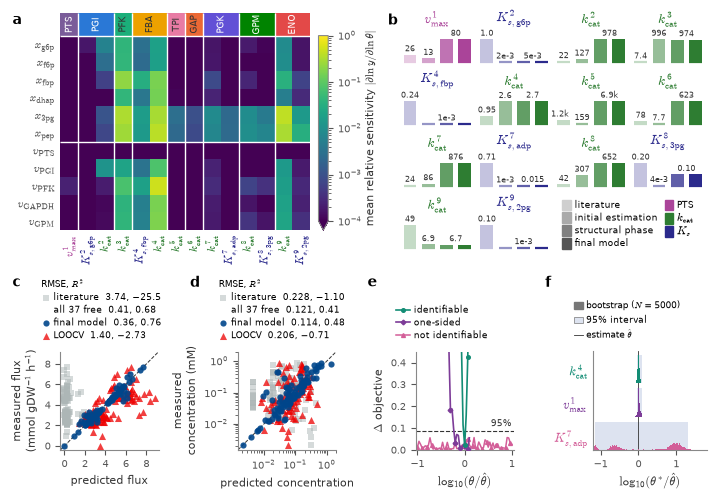

In [6]:
plt.rcdefaults()
plt.rcParams.update(S.RC)
plt.rcParams.update({"mathtext.fontset": "cm"})   # equations in the LaTeX font (Computer Modern)

# colours of the models in c and d (Lancet palette) and of the three parameters of e and f (jewel tones, other hues so that
# they do not read as models): each parameter has the same colour in its profile and in its bootstrap distribution
C_LIT = "#ADB6B6"
C_FINAL = "#00468B"
C_LOOCV = "#ED0000"
C_INTERVAL = "#dde3f0"
C_IDENTIFIABLE = "#138D75"
C_ONE_SIDED = "#7D3C98"
C_FLAT = "#D35E98"
MINUS = "\u2212"   # true minus sign for the negative R^2 values

# layout: two rows at the full text width of the paper (516 pt after the tight crop, used at \linewidth); the grid spans
# the default 0.77 of the figure height (top 0.88, bottom 0.11), so the row heights are inches
ROW1_H = 2.45    # heatmap with its reaction header and its column labels; b spans the whole row
GAP1_H = 0.93    # room for the legends above c to f
ROW2_H = 0.986   # c, d and e are squares of this side (71 pt); f is a little wider
FIG_H = (ROW1_H + GAP1_H + ROW2_H) / 0.77
A_HEADER_ROWS = 1.25   # height of the reaction header, in heatmap rows
A_LABEL_ROWS = 1.6     # room for the rotated column labels under the heatmap, in heatmap rows
LETTER_X = -34.5       # panel letters sit this many points left of their axes
ROW2_LEGEND_X = -22.0  # the legends above c to f start this many points left of their axes, right after the letter
n_rows = len(heatmap_row_labels)
n_cols = len(free)

fig = plt.figure(figsize=(7.26, FIG_H))
gs = fig.add_gridspec(3, 1, height_ratios=[ROW1_H, GAP1_H, ROW2_H], hspace=0.0, left=0.09, right=0.98)
gs_top = gs[0].subgridspec(3, 2, width_ratios=[1.0, 1.12], height_ratios=[A_HEADER_ROWS, n_rows, A_LABEL_ROWS], wspace=0.22, hspace=0.0)
gs_mid = gs[2].subgridspec(1, 4, width_ratios=[1.0, 1.0, 1.0, 1.155], wspace=0.777)
ax_a = fig.add_subplot(gs_top[1, 0])
ax_b = fig.add_subplot(gs_top[:, 1])
ax_c = fig.add_subplot(gs_mid[0, 0])
ax_d = fig.add_subplot(gs_mid[0, 1])
ax_e = fig.add_subplot(gs_mid[0, 2])
ax_f = fig.add_subplot(gs_mid[0, 3])

# ---- (a) sensitivity heatmap ----
im = ax_a.imshow(H, aspect="auto", cmap="viridis", norm=LogNorm(vmin=1e-4, vmax=1.0))
ax_a.set_facecolor("#e6e6e6")
ax_a.set_xticks(range(n_cols))
ax_a.set_xticklabels(col_labels, rotation=90, fontsize=8)
for tick, p in zip(ax_a.get_xticklabels(), free):
    tick.set_color(TYPE_COLOR[type_of(p)])

ax_a.set_yticks(range(n_rows))
ax_a.set_yticklabels(heatmap_row_labels, fontsize=8.5)
# reaction header (one coloured block per reaction, names rotated like the column labels, in white or ink, whichever
# reads better on the block) on top; the same thin white line separates the header from the heatmap, the reactions
# (through header and heatmap) and the metabolites from the fluxes
A_LINE = 1.0
A_HEADER_TOP = -0.5 - A_HEADER_ROWS
for r in sorted(set(col_rxn)):
    cols_r = [j for j, rr in enumerate(col_rxn) if rr == r]
    block_colour = S.REACTION_COLOR[r - 1]
    ax_a.add_patch(Rectangle((cols_r[0] - 0.5, A_HEADER_TOP), len(cols_r), A_HEADER_ROWS, color=block_colour, lw=0, clip_on=False))
    ax_a.text(float(np.mean(cols_r)), A_HEADER_TOP + A_HEADER_ROWS / 2, S.REACTIONS[r - 1][:3], ha="center", va="center", rotation=90, fontsize=6.3, color=text_colour_on(block_colour), clip_on=False)

ax_a.plot([-0.5, n_cols - 0.5], [-0.5, -0.5], color="white", lw=A_LINE, solid_capstyle="butt", clip_on=False)
ax_a.plot([-0.5, n_cols - 0.5], [len(rows_met) - 0.5, len(rows_met) - 0.5], color="white", lw=A_LINE, solid_capstyle="butt")
for j in range(1, n_cols):
    if col_rxn[j] != col_rxn[j - 1]:
        ax_a.plot([j - 0.5, j - 0.5], [A_HEADER_TOP, n_rows - 0.5], color="white", lw=A_LINE, solid_capstyle="butt", clip_on=False)

ax_a.set_ylim(n_rows - 0.5, -0.5)
ax_a.tick_params(length=0)
for sp in ax_a.spines.values():
    sp.set_visible(False)

cb = fig.colorbar(im, ax=ax_a, fraction=0.06, pad=0.03, extend="min")   # the pointed end: values below 1e-4
cb.set_label("mean relative sensitivity $|\\partial \\ln y / \\partial \\ln \\theta|$", fontsize=8, labelpad=2)
cb.ax.tick_params(labelsize=7)
ax_a.annotate("a", xy=(-0.5, A_HEADER_TOP), xycoords="data", xytext=(LETTER_X, 0), textcoords="offset points", ha="left", va="top", fontsize=10, fontweight="bold", annotation_clip=False)

# ---- (b) parameter values after every phase, one group of bars per parameter ----
B_COLS = 4
B_STEP = 4.2
B_ROW_STEP = 2.3
B_BAR_HEIGHT = 0.85
for g, p in enumerate(free):
    x0 = (g % B_COLS) * B_STEP
    y0 = -(g // B_COLS) * B_ROW_STEP
    values = stage_values[p]
    top = max(values)
    colour = TYPE_COLOR[type_of(p)]
    for i, v in enumerate(values):
        ax_b.bar(x0 + i, B_BAR_HEIGHT * v / top, bottom=y0, width=0.7, color=lighter(colour, STAGE_LIGHTNESS[i]), lw=0)
        # a short floor in the bar's shade, so that bars of near-zero height still show their phase
        ax_b.plot([x0 + i - 0.35, x0 + i + 0.35], [y0, y0], color=lighter(colour, STAGE_LIGHTNESS[i]), lw=1.6, solid_capstyle="butt")
    for x_label, height, text in stage_labels[p]:
        ax_b.text(x0 + x_label, y0 + B_BAR_HEIGHT * height + 0.05, text, ha="center", va="bottom", fontsize=6.0, color=S.INK)
    ax_b.text(x0 + 1.5, y0 + 1.28, S.label(p), ha="center", va="bottom", fontsize=9.5, color=colour)

ax_b.set_xlim(-0.6, (B_COLS - 1) * B_STEP + 3.6)
ax_b.set_ylim(-3 * B_ROW_STEP - 0.4, 1.8)
ax_b.axis("off")
b_handles = []
b_names = ["literature", "initial estimation", "structural phase", "final model"]
for i, name in enumerate(b_names):
    b_handles.append(Patch(color=lighter("#555555", STAGE_LIGHTNESS[i]), label=name))

b_handles.append(Patch(color=TYPE_COLOR["PTS"], label="PTS"))
b_handles.append(Patch(color=TYPE_COLOR["kcat"], label="$k_{\\mathrm{cat}}$"))
b_handles.append(Patch(color=TYPE_COLOR["K"], label="$K_s$"))
# the last legend row on the baseline of the last row of bars; rows as tall as the 8 pt math names, so both columns line up
b_legend = ax_b.legend(handles=b_handles, loc="lower left", bbox_to_anchor=(0.52, 0.026), ncol=2, frameon=False, fontsize=6.3, handlelength=1.0, handleheight=1.55, handletextpad=0.4, columnspacing=0.8, labelspacing=0.2, borderaxespad=0.0)
# the math names of the types at 8 pt, so that their subscripts ('cat', 's') stay readable
b_legend.get_texts()[5].set_fontsize(8)
b_legend.get_texts()[6].set_fontsize(8)
ax_b.annotate("b", xy=(0, 1), xycoords="axes fraction", xytext=(-8, 0), textcoords="offset points", ha="left", va="top", fontsize=10, fontweight="bold")

# ---- (c) LI flux parity (markers without borders, slightly transparent, so that dense regions stay readable) ----
ax_c.plot([-0.4, 9.2], [-0.4, 9.2], color=S.INK, lw=0.7, ls="--", zorder=1)
c_literature = ax_c.scatter(fx_lit, fy_lit, s=22, marker="s", color=C_LIT, lw=0, alpha=0.5, zorder=2, label=("literature  %.2f, %.1f" % (m.loc["literature", "rmse_flux_li"], m.loc["literature", "r2_flux_li_permean"])).replace("-", MINUS))
# the initial estimation (all parameters free) fits almost like the final model: only its metrics, in the legend
c_all_free = Line2D([], [], color="none", label=("all %d free  %.2f, %.2f" % (len(ALL_PARAMS), m.loc["stage0", "rmse_flux_li"], m.loc["stage0", "r2_flux_li_permean"])).replace("-", MINUS))
c_final = ax_c.scatter(fx_f, fy_f, s=20, marker="o", color=C_FINAL, lw=0, alpha=0.9, zorder=5, label=("final model  %.2f, %.2f" % (m.loc["final", "rmse_flux_li"], m.loc["final", "r2_flux_li_permean"])).replace("-", MINUS))
c_loocv = ax_c.scatter(fx_l, fy_l, s=26, marker="^", color=C_LOOCV, lw=0, alpha=0.75, zorder=4, label=("LOOCV  %.2f, %.2f" % (m.loc["loocv", "rmse_flux_li"], m.loc["loocv", "r2_flux_li_permean"])).replace("-", MINUS))
ax_c.set_xlim(-0.4, 9.2)
ax_c.set_ylim(-0.4, 9.2)
ax_c.set_aspect("equal")
ax_c.set_xticks([0, 2, 4, 6, 8])
ax_c.set_yticks([0, 2, 4, 6, 8])
ax_c.set_xlabel("predicted flux")
ax_c.set_ylabel("measured flux\n(mmol gDW$^{-1}$ h$^{-1}$)")
c_legend = ax_c.legend(handles=[c_literature, c_all_free, c_final, c_loocv], title="RMSE, $R^2$", title_fontsize=6.3, alignment="left", loc="lower left", bbox_to_anchor=(0.0, 1.0), bbox_transform=offset_copy(ax_c.transAxes, fig=fig, x=ROW2_LEGEND_X, y=0, units="points"), frameon=False, fontsize=6.3, handlelength=1.0, handletextpad=0.4, borderaxespad=0.9, labelspacing=0.3)
# the letters of c to f: level with the top of the legend of c
ax_c.annotate("c", xy=(0, 1), xycoords=("axes fraction", c_legend), xytext=(LETTER_X, 0), textcoords="offset points", ha="left", va="top", fontsize=10, fontweight="bold")

# ---- (d) metabolite parity (log-log) ----
ax_d.plot([1.5e-3, 2], [1.5e-3, 2], color=S.INK, lw=0.7, ls="--", zorder=1)
d_literature = ax_d.scatter(mx_lit, my_lit, s=22, marker="s", color=C_LIT, lw=0, alpha=0.5, zorder=2, label=("literature  %.3f, %.2f" % (m.loc["literature", "rmse_met"], m.loc["literature", "r2_met_permean"])).replace("-", MINUS))
d_all_free = Line2D([], [], color="none", label=("all %d free  %.3f, %.2f" % (len(ALL_PARAMS), m.loc["stage0", "rmse_met"], m.loc["stage0", "r2_met_permean"])).replace("-", MINUS))
d_final = ax_d.scatter(mx_f, my_f, s=20, marker="o", color=C_FINAL, lw=0, alpha=0.9, zorder=5, label=("final model  %.3f, %.2f" % (m.loc["final", "rmse_met"], m.loc["final", "r2_met_permean"])).replace("-", MINUS))
d_loocv = ax_d.scatter(mx_l, my_l, s=26, marker="^", color=C_LOOCV, lw=0, alpha=0.75, zorder=4, label=("LOOCV  %.3f, %.2f" % (m.loc["loocv", "rmse_met"], m.loc["loocv", "r2_met_permean"])).replace("-", MINUS))
ax_d.set_xscale("log")
ax_d.set_yscale("log")
ax_d.set_xlim(1.5e-3, 2)
ax_d.set_ylim(1.5e-3, 2)
ax_d.set_aspect("equal")
ax_d.set_xlabel("predicted concentration")
ax_d.set_ylabel("measured\nconcentration (mM)")
ax_d.legend(handles=[d_literature, d_all_free, d_final, d_loocv], title="RMSE, $R^2$", title_fontsize=6.3, alignment="left", loc="lower left", bbox_to_anchor=(0.0, 1.0), bbox_transform=offset_copy(ax_d.transAxes, fig=fig, x=ROW2_LEGEND_X, y=0, units="points"), frameon=False, fontsize=6.3, handlelength=1.0, handletextpad=0.4, borderaxespad=0.9, labelspacing=0.3)
ax_d.annotate("d", xy=(0, 1), xycoords=("axes fraction", c_legend), xytext=(LETTER_X, 0), textcoords="offset points", ha="left", va="top", fontsize=10, fontweight="bold")

# ---- (e) profile likelihood: identifiable, crossing on one side, flat ----
ax_e.plot(h_identifiable["log10_offset"], h_identifiable["obj"] - obj_hat, "-o", ms=2.6, markevery=3, lw=1.2, color=C_IDENTIFIABLE, zorder=4, label="identifiable")
ax_e.plot(h_one_sided["log10_offset"], h_one_sided["obj"] - obj_hat, "-D", ms=2.4, markevery=3, lw=1.2, color=C_ONE_SIDED, zorder=3, label="one-sided")
ax_e.plot(h_flat["log10_offset"], h_flat["obj"] - obj_hat, "-^", ms=2.8, markevery=3, lw=1.1, color=C_FLAT, zorder=2, label="not identifiable")
ax_e.axhline(lr, color=S.INK, lw=0.8, ls="--", zorder=1)
ax_e.text(METHOD["profile_span"], lr + 0.012, "95%", ha="right", va="bottom", fontsize=6.3, color=S.INK)
ax_e.set_box_aspect(1)
ax_e.set_xlim(-1.04 * METHOD["profile_span"], 1.04 * METHOD["profile_span"])
ax_e.set_xticks([-METHOD["profile_span"], 0, METHOD["profile_span"]])
ax_e.set_ylim(0, 0.45)
ax_e.set_xlabel("$\\mathrm{log}_{10}(\\theta / \\hat{\\theta})$", fontsize=9, labelpad=2.5)
ax_e.set_ylabel("$\\Delta$ objective")
ax_e.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), bbox_transform=offset_copy(ax_e.transAxes, fig=fig, x=ROW2_LEGEND_X, y=0, units="points"), frameon=False, fontsize=6.3, handlelength=1.6, handletextpad=0.4, borderaxespad=0.9, labelspacing=0.3)
ax_e.annotate("e", xy=(0, 1), xycoords=("axes fraction", c_legend), xytext=(LETTER_X, 0), textcoords="offset points", ha="left", va="top", fontsize=10, fontweight="bold")

# ---- (f) ridgeline of the bootstrap distributions of the three parameters of e, each scaled to its own peak ----
# one linear axis for all three, so that the widths compare directly (the shapes are in the supplementary figure)
F_LIMITS = (-1.2, 1.8)
F_BINS = np.linspace(F_LIMITS[0], F_LIMITS[1], 151)
F_HEIGHT = 0.85   # height of a ridge; the ridges sit one unit apart

p = best_param
y0 = 2.0
counts = np.histogram(boot_log[p], bins=F_BINS)[0]
ax_f.add_patch(Rectangle((boot_interval[p][0], y0), boot_interval[p][1] - boot_interval[p][0], F_HEIGHT, color=C_INTERVAL, lw=0, zorder=0))
ax_f.fill_between(F_BINS, y0, y0 + F_HEIGHT * np.append(counts, counts[-1]) / counts.max(), step="post", color=C_IDENTIFIABLE, lw=0, zorder=2)

p = one_sided_param
y0 = 1.0
counts = np.histogram(boot_log[p], bins=F_BINS)[0]
ax_f.add_patch(Rectangle((boot_interval[p][0], y0), boot_interval[p][1] - boot_interval[p][0], F_HEIGHT, color=C_INTERVAL, lw=0, zorder=0))
ax_f.fill_between(F_BINS, y0, y0 + F_HEIGHT * np.append(counts, counts[-1]) / counts.max(), step="post", color=C_ONE_SIDED, lw=0, zorder=2)

p = flat_example
y0 = 0.0
counts = np.histogram(boot_log[p], bins=F_BINS)[0]
ax_f.add_patch(Rectangle((boot_interval[p][0], y0), boot_interval[p][1] - boot_interval[p][0], F_HEIGHT, color=C_INTERVAL, lw=0, zorder=0))
ax_f.fill_between(F_BINS, y0, y0 + F_HEIGHT * np.append(counts, counts[-1]) / counts.max(), step="post", color=C_FLAT, lw=0, zorder=2)

f_estimate_line = ax_f.axvline(0.0, color=S.INK, lw=0.6, zorder=1, label="estimate $\\hat{\\theta}$")
ax_f.set_xlim(*F_LIMITS)
ax_f.set_ylim(0, 2.95)
ax_f.set_xticks([-1, 0, 1])
ax_f.set_yticks([2.4, 1.4, 0.4])
ax_f.set_yticklabels([S.label(best_param), S.label(one_sided_param), S.label(flat_example)], fontsize=9)
ax_f.get_yticklabels()[0].set_color(C_IDENTIFIABLE)
ax_f.get_yticklabels()[1].set_color(C_ONE_SIDED)
ax_f.get_yticklabels()[2].set_color(C_FLAT)
ax_f.tick_params(axis="y", length=0)
ax_f.set_xlabel("$\\mathrm{log}_{10}(\\theta^{*} / \\hat{\\theta})$", fontsize=9, labelpad=2.5)
f_resample_key = Patch(color=S.MUTED, label="bootstrap ($N$ = %d)" % len(boot))
f_interval_key = Patch(facecolor=C_INTERVAL, edgecolor=S.MUTED, linewidth=0.5, label="95% interval")
ax_f.legend(handles=[f_resample_key, f_interval_key, f_estimate_line], loc="lower left", bbox_to_anchor=(0.0, 1.0), bbox_transform=offset_copy(ax_f.transAxes, fig=fig, x=ROW2_LEGEND_X, y=0, units="points"), frameon=False, fontsize=6.3, handlelength=1.0, handletextpad=0.4, borderaxespad=0.9, labelspacing=0.47)
ax_f.annotate("f", xy=(0, 1), xycoords=("axes fraction", c_legend), xytext=(LETTER_X, 0), textcoords="offset points", ha="left", va="top", fontsize=10, fontweight="bold")

fig.savefig(os.path.join(MAIN_FIGURE, "fig2_conference.png"), bbox_inches="tight")
fig.savefig(os.path.join(MAIN_FIGURE, "fig2_conference.pdf"), bbox_inches="tight")

plt.show()